<a href="https://colab.research.google.com/github/Immanuel-Leonard/Churn-Analysis-/blob/main/Churn_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from datasets import load_dataset
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


df = load_dataset("aai510-group1/telco-customer-churn")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md:   0%|          | 0.00/11.9k [00:00<?, ?B/s]

train.csv:   0%|          | 0.00/1.13M [00:00<?, ?B/s]

validation.csv:   0%|          | 0.00/378k [00:00<?, ?B/s]

test.csv:   0%|          | 0.00/379k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/4225 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1409 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1409 [00:00<?, ? examples/s]

In [ ]:
# Check dataset
df['test'].to_pandas().head()

,Age,Avg Monthly GB Download,Avg Monthly Long Distance Charges,Churn,Churn Category,Churn Reason,Churn Score,City,CLTV,Contract,...,Streaming TV,Tenure in Months,Total Charges,Total Extra Data Charges,Total Long Distance Charges,Total Refunds,Total Revenue,Under 30,Unlimited Data,Zip Code
0,39,29,18.91,0,None,None,54,Bradley,3334,One Year,...,1,7,477.05,0,132.37,0.0,609.42,0,1,93426
1,75,22,33.48,0,None,None,54,Lakeshore,2455,Month-to-Month,...,1,30,3181.80,0,1004.40,0.0,4186.20,0,1,93634
2,67,14,9.96,0,None,None,26,Lompoc,5011,Two Year,...,1,71,7904.25,0,707.16,0.0,8611.41,0,1,93437
3,47,7,34.64,0,None,None,29,Echo Lake,2452,Month-to-Month,...,1,9,593.85,0,311.76,0.0,905.61,0,1,95721
4,21,0,10.49,0,None,None,23,Lancaster,4129,One Year,...,0,25,507.90,0,262.25,0.0,770.15,1,0,93536


In [ ]:
df['test'].to_pandas().tail()

,Age,Avg Monthly GB Download,Avg Monthly Long Distance Charges,Churn,Churn Category,Churn Reason,Churn Score,City,CLTV,Contract,...,Streaming TV,Tenure in Months,Total Charges,Total Extra Data Charges,Total Long Distance Charges,Total Refunds,Total Revenue,Under 30,Unlimited Data,Zip Code
1404,33,12,10.67,0,None,None,53,Clayton,4847,Month-to-Month,...,1,29,2878.75,0,309.43,0.0,3188.18,0,1,94517
1405,36,30,30.44,0,None,None,45,Nicolaus,5470,Two Year,...,1,59,5655.45,0,1795.96,0.0,7451.41,0,1,95659
1406,57,24,4.51,0,None,None,74,Walnut Creek,4471,Two Year,...,1,61,5175.30,0,275.11,0.0,5450.41,0,1,94596
1407,35,24,47.06,0,None,None,70,Valyermo,5445,Two Year,...,0,30,1653.85,0,1411.80,0.0,3065.65,0,1,93563
1408,54,24,12.85,0,None,None,70,Rancho Cucamonga,5065,Two Year,...,1,72,7998.80,70,925.20,0.0,8994.00,0,0,91701


In [ ]:
df['test'].to_pandas().shape

(1409, 52)

In [ ]:
# Average Churn Score

churn_avg = df['test'].to_pandas()['Churn Score'].mean()
print('%.2f' % churn_avg)

59.05


In [ ]:


# Customers per zip code
# Calculate the count of each unique zip code in the 'Zip Code' column
if 'Zip Code' in df['test'].column_names:
    zip_code_counts = df['test'].to_pandas()['Zip Code'].value_counts()
    print("Customers per Zip Code:")
    display(zip_code_counts)
else:
    print("Error: 'test' or 'Zip Code' column not found in the dataset.")

Customers per Zip Code:


,count
Zip Code,
92028,12
92109,9
92027,6
92122,5
92126,5
...,...
96063,1
95356,1
94513,1


In [ ]:
# Filter zip codes where the count of customers is greater than 2
filtered_zip_code_counts = zip_code_counts[zip_code_counts > 2]
display(filtered_zip_code_counts)


,count
Zip Code,
92028,12
92109,9
92027,6
92122,5
92126,5
92130,5
91354,4
92592,4
92129,4


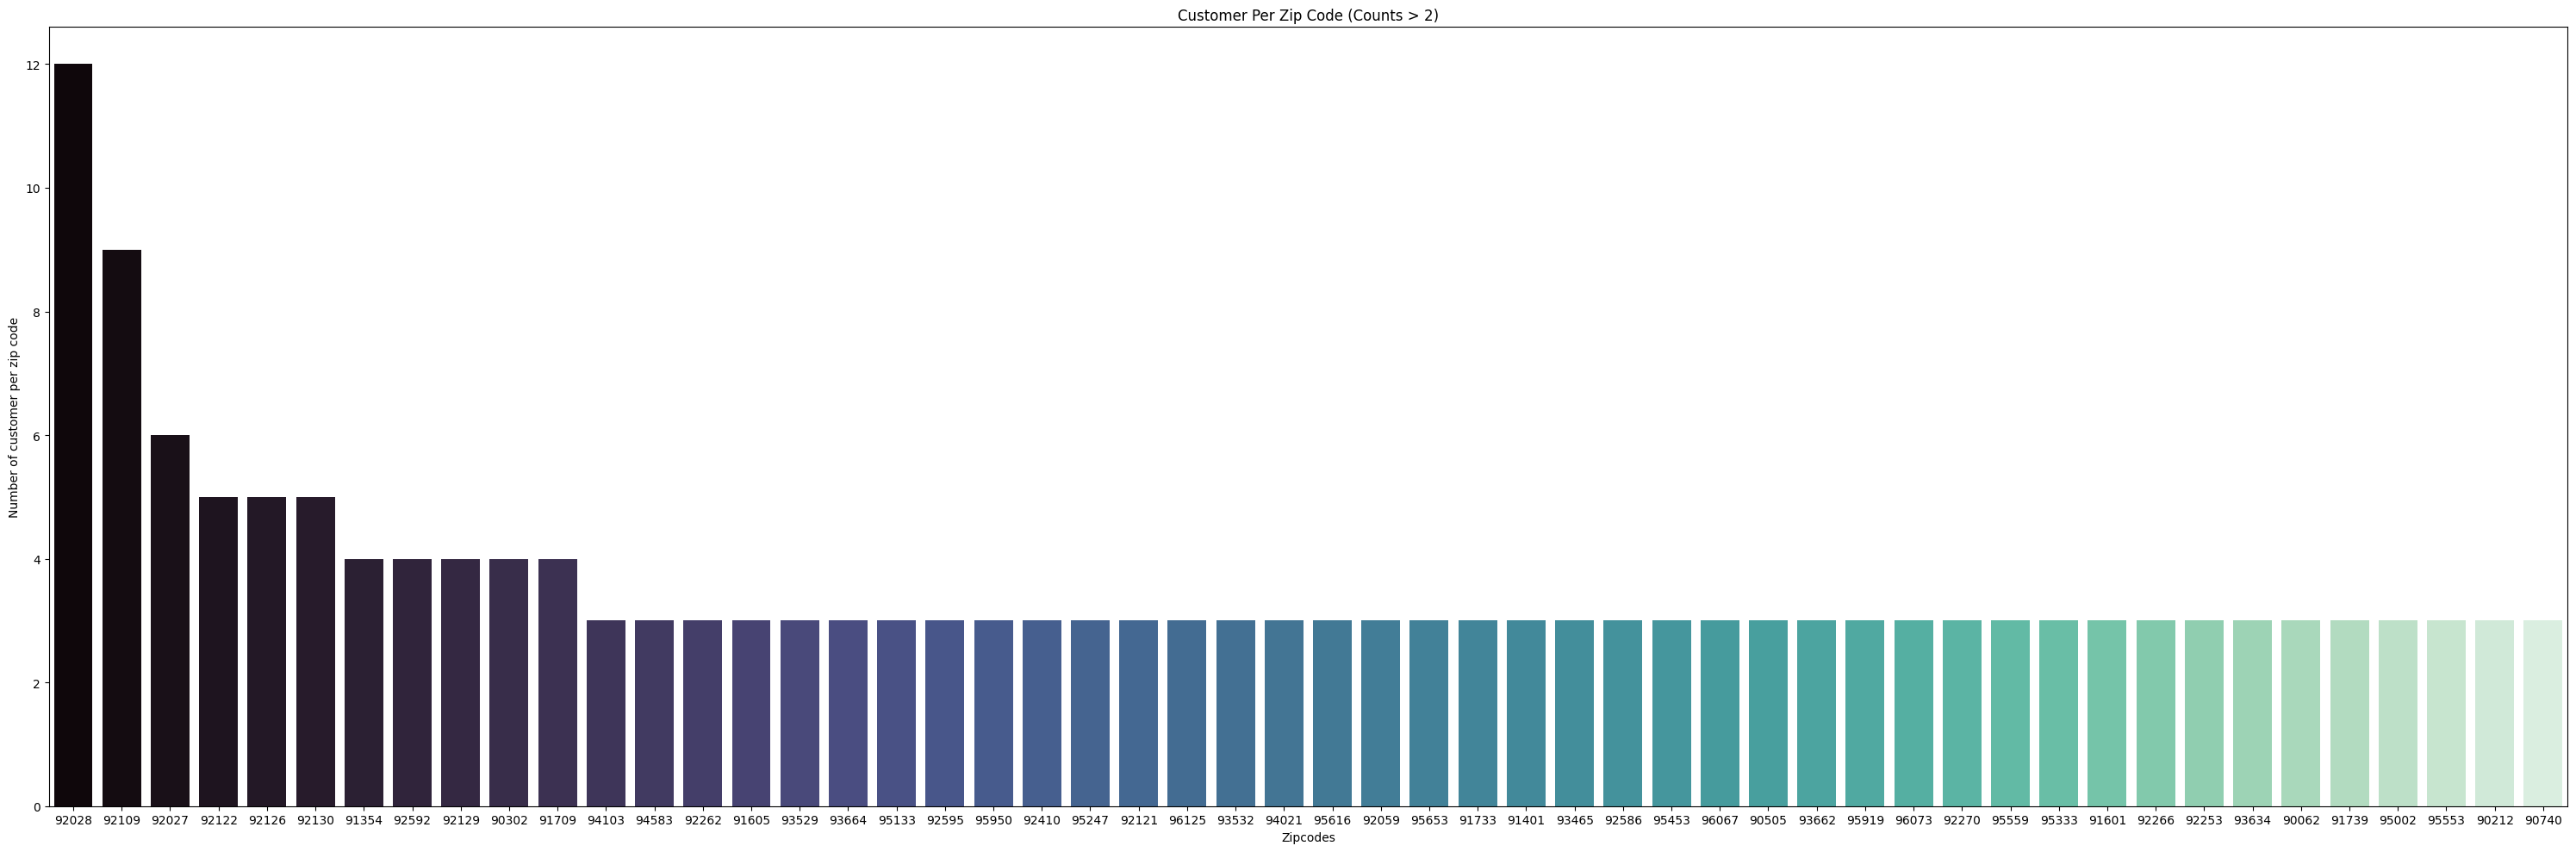

In [ ]:


#plot if there are zip codes
if not filtered_zip_code_counts.empty:
  plt.figure(figsize = (30, 10))
  sns.barplot(x = filtered_zip_code_counts.index, y = filtered_zip_code_counts.values, hue = filtered_zip_code_counts.index, palette = 'mako', legend = False)
  plt.title('Customer Per Zip Code (Counts > 2)')
  plt.xlabel("Zipcodes")
  plt.ylabel("Number of customer per zip code")
  plt.tight_layout()
  plt.show()
else:
  print("No zip codes found with more than 1 customer.")

In [ ]:
# Tenure months avg churn score
churn_score = df['test'].to_pandas()['Churn Score'].sort_values()
tenure_monts = df['test'].to_pandas()['Tenure in Months'].sort_values()
print(churn_score)
print(tenure_monts)
churn_tenure = pd.DataFrame([churn_score, tenure_monts])
print(churn_tenure)

1294     7
314      9
33       9
1196    20
486     20
        ..
707     96
154     96
607     96
360     96
64      96
Name: Churn Score, Length: 1409, dtype: int64
13       1
19       1
678      1
83       1
89       1
        ..
1345    72
978     72
1349    72
10      72
1408    72
Name: Tenure in Months, Length: 1409, dtype: int64
                  1294  314   33    1196  486   495   680   863   446   287   \
Churn Score          7     9     9    20    20    20    20    20    20    20   
Tenure in Months    13    72    23    71    53    68    64     3    58    72   

                  ...  844   589   1200  285   931   707   154   607   360   \
Churn Score       ...    95    95    96    96    96    96    96    96    96   
Tenure in Months  ...     9     4    18    42     5     3    32    17     1   

                  64    
Churn Score         96  
Tenure in Months    12  

[2 rows x 1409 columns]


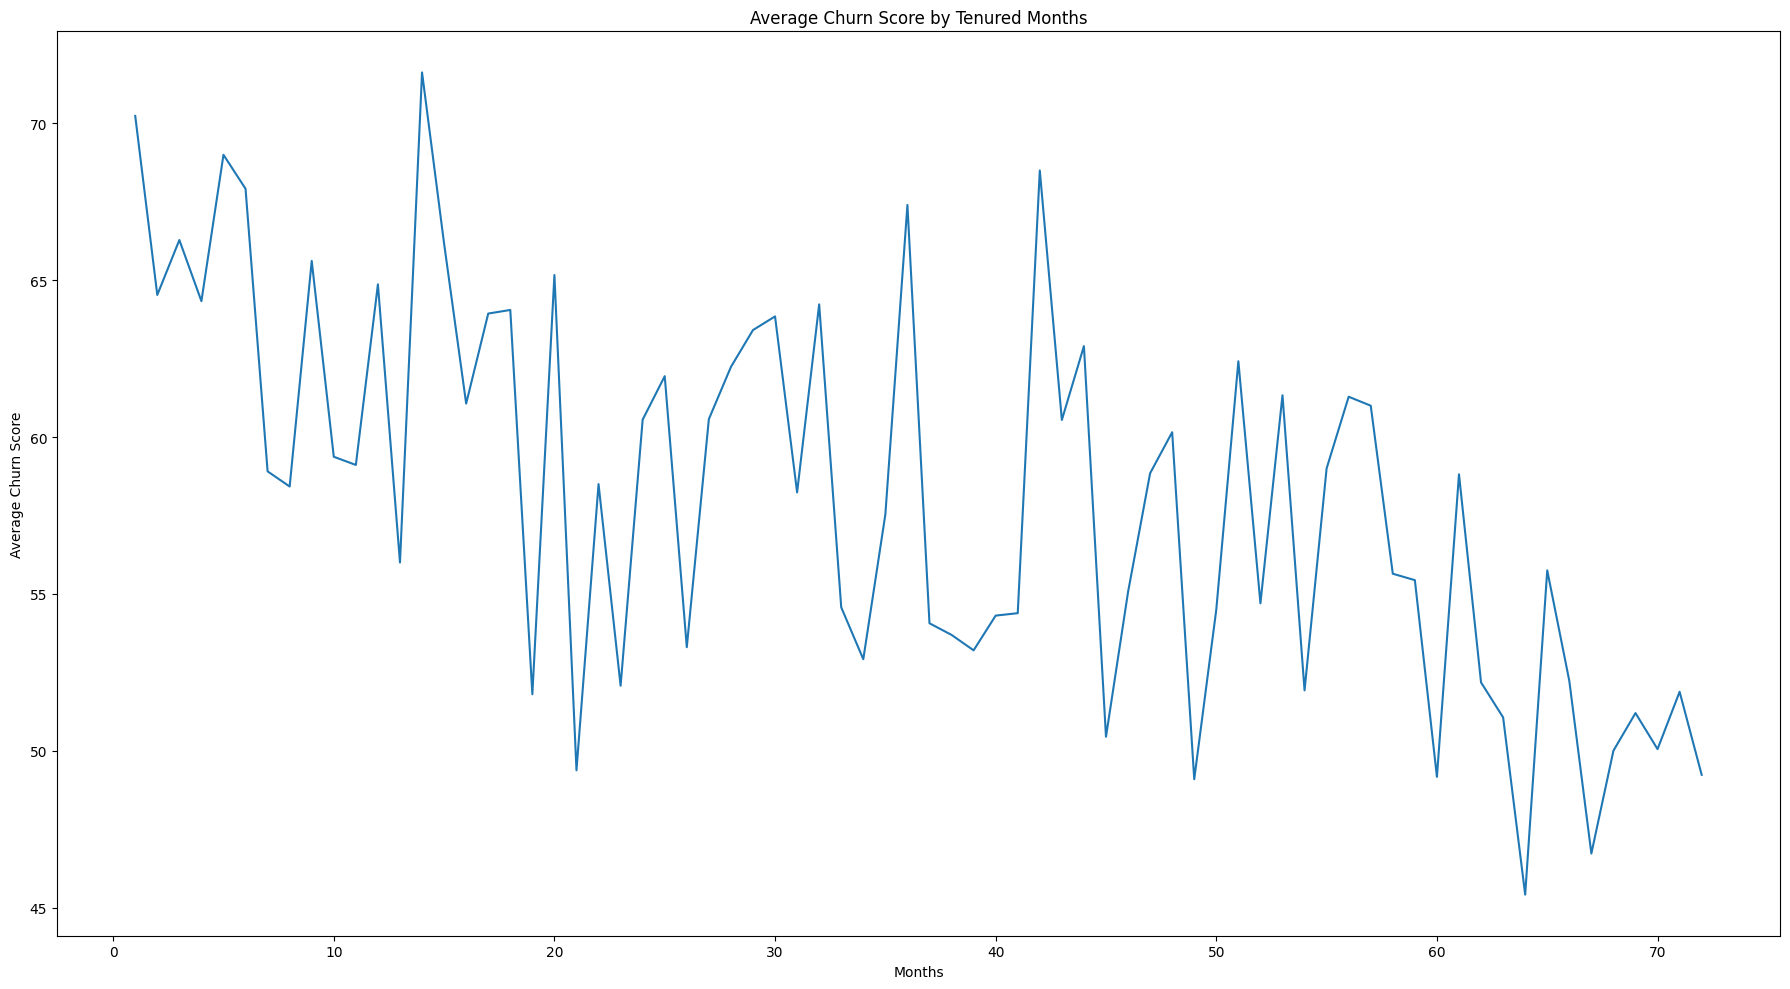

In [ ]:


# Visualize tenure months to churn score

original_df = df['test'].to_pandas()
churn_tenure_grouped = original_df.groupby('Tenure in Months')['Churn Score'].mean().reset_index()

plt.figure(figsize = (18, 10))
plt.plot(churn_tenure_grouped['Tenure in Months'], churn_tenure_grouped['Churn Score'])
plt.title('Average Churn Score by Tenured Months')
plt.xlabel('Months')
plt.ylabel('Average Churn Score')
plt.tight_layout()
plt.show()

In [ ]:
# Avg age of customers
avg_age = original_df['Age'].mean()
print('%.2f' %avg_age)

# Number of custmers per age
age_count = original_df.groupby('Age')['Age'].count()


46.62


In [ ]:
# Churn Score avg by age
original_df.groupby('Age')['Churn Score'].mean().sort_values().sort_index()

,Churn Score
Age,
19,54.333333
20,64.444444
21,55.518519
22,56.441176
23,55.705882
...,...
76,57.357143
77,72.285714
78,72.777778


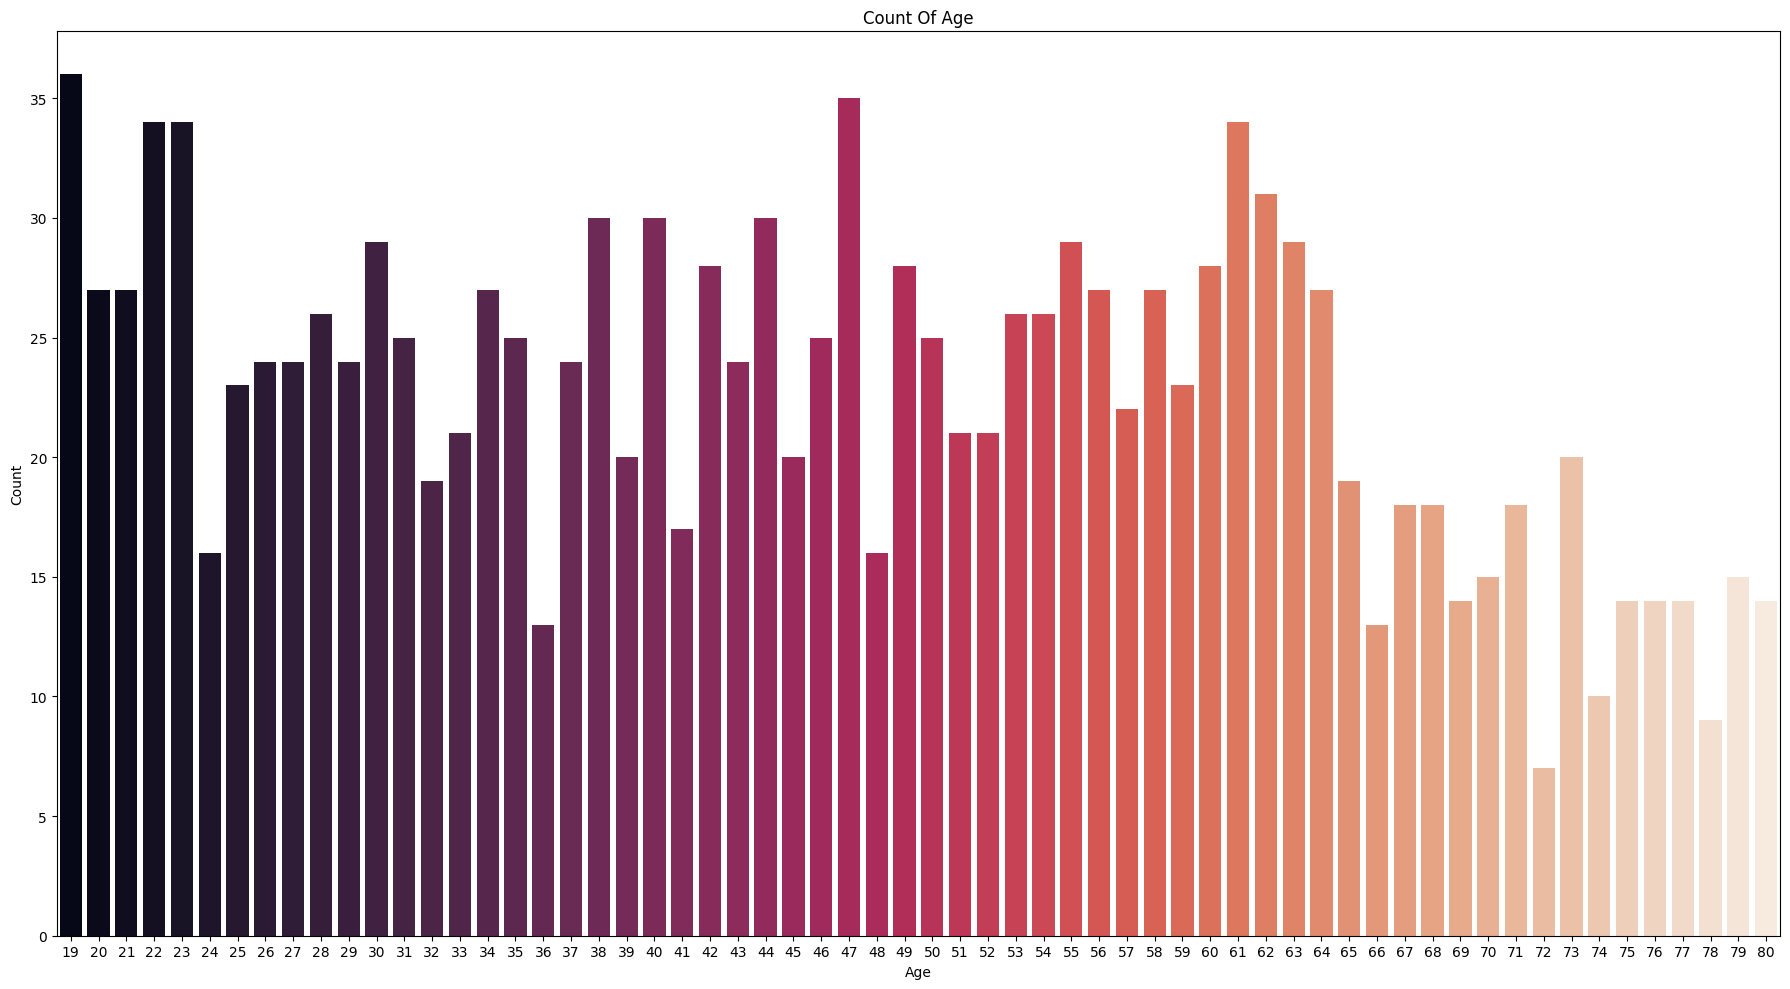

In [ ]:

# Visualize customer count by age
plt.figure(figsize = (18, 10))
sns.barplot(x = age_count.index, y = age_count.values, hue = age_count.index, palette = 'rocket', legend = False)
plt.title('Count Of Age')
plt.xlabel('Age')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

In [ ]:
# age groups (bins)
age_bins = [18, 30, 40, 50, 60, 70, 80, 90]
age_labels = ['18-29', '30-39', '40-49', '50-59', '60-69', '70-79', '80+']

# Create a new column
original_df['Age Group'] = pd.cut(original_df['Age'], bins=age_bins, labels=age_labels, right=False)

#  churn count and total count for each age group
age_group_churn = original_df.groupby('Age Group')['Churn'].agg(['sum', 'count'])
age_group_churn.columns = ['Churned Customers', 'Total Customers']

# churn percentage for each age group
age_group_churn['Churn Percentage'] = (age_group_churn['Churned Customers'] / age_group_churn['Total Customers']) * 100

# Display the results
display(age_group_churn.round(2))

/tmp/ipykernel_2679/2077565956.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  age_group_churn = original_df.groupby('Age Group')['Churn'].agg(['sum', 'count'])


,Churned Customers,Total Customers,Churn Percentage
Age Group,,,
18-29,67,295,22.71
30-39,52,233,22.32
40-49,63,253,24.90
50-59,62,247,25.10
60-69,66,231,28.57
70-79,59,136,43.38
80+,5,14,35.71


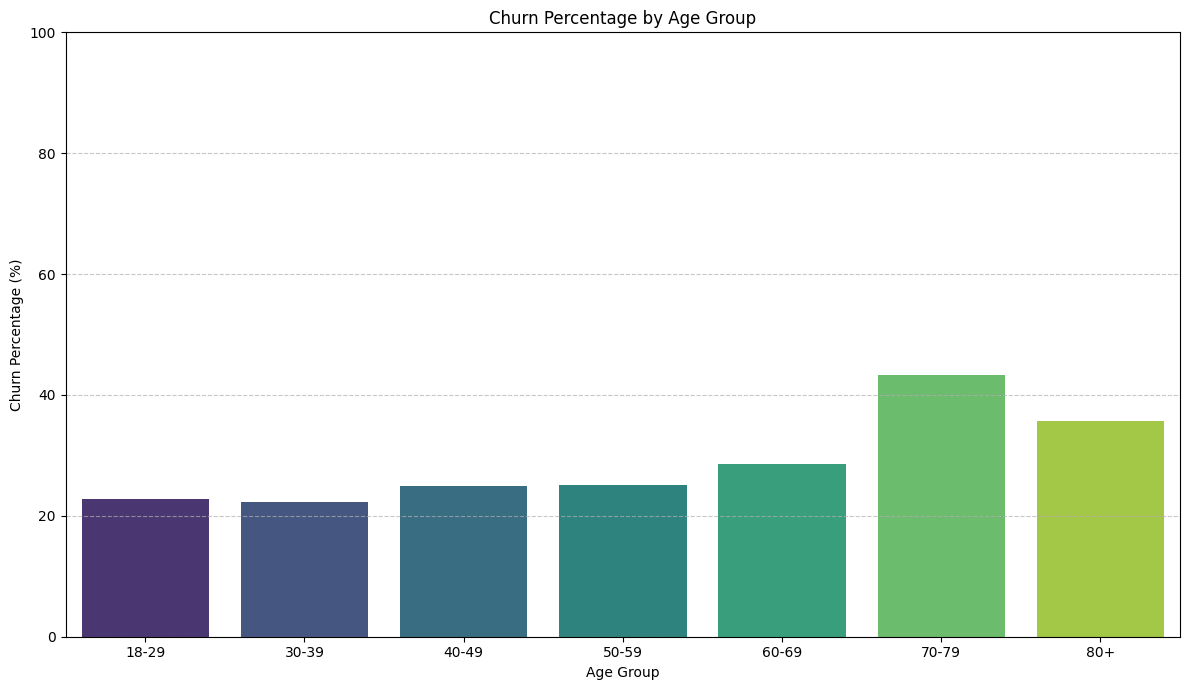

In [ ]:



# Chart the churn percentage by age group
plt.figure(figsize=(12, 7))
sns.barplot(x=age_group_churn.index, y=age_group_churn['Churn Percentage'], hue = age_group_churn.index , palette= 'viridis', legend = False)
plt.title('Churn Percentage by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Churn Percentage (%)')
plt.ylim(0, 100)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [ ]:
# Filter nulls anf count on churn reason
churn_reason = original_df[original_df['Churn Reason'] != 'None'].groupby("Churn Reason").size().sort_values(ascending = False)
display(churn_reason)

,0
Churn Reason,
Competitor had better devices,55
Competitor made better offer,55
Attitude of support person,43
Competitor offered more data,34
Competitor offered higher download speeds,25
Price too high,22
Attitude of service provider,21
Product dissatisfaction,21
Don't know,21


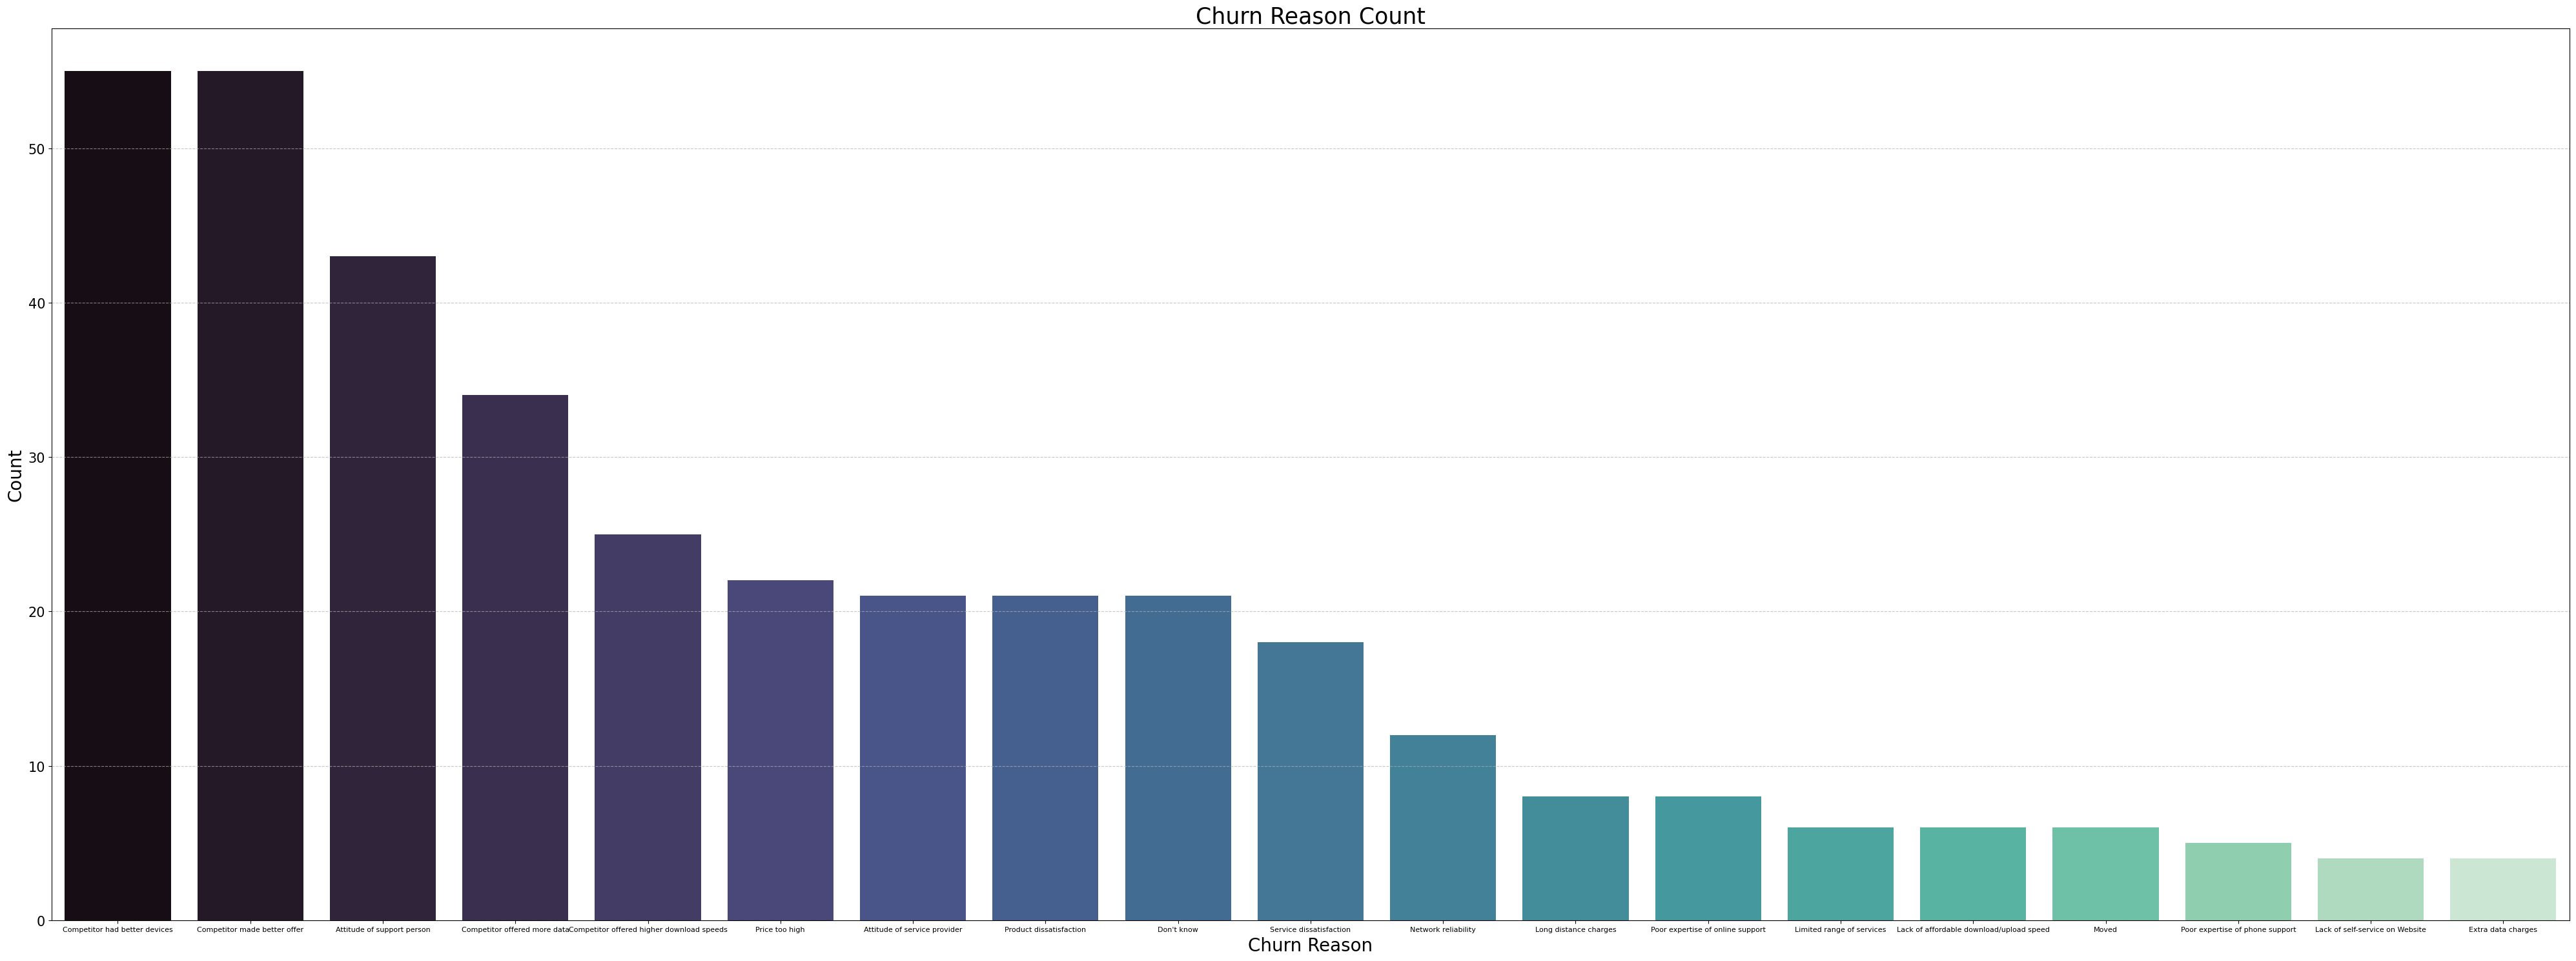

In [ ]:

# Visualize churn reason
plt.figure(figsize=(40,15))
sns.barplot(x = churn_reason.index , y = churn_reason.values, hue = churn_reason.index , palette = 'mako', legend = False )
plt.title("Churn Reason Count", fontsize=25)
plt.xlabel('Churn Reason', fontsize=20)
plt.ylabel('Count', fontsize=20)
plt.xticks(fontsize= 8)
plt.yticks(fontsize=15)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [ ]:
# Customers per city
city_count = original_df['City'].value_counts()
# Filter to display only cities with more than 10 customers
filtered_city_count = city_count[city_count > 10]
display(filtered_city_count)

,count
City,
Los Angeles,59
San Diego,56
San Jose,30
San Francisco,25
Sacramento,19
Fresno,17
Oakland,12
Fallbrook,12


In [ ]:
# Churn rate for each location
churn_per_location = original_df.groupby('City')['Churn Score'].mean().reset_index()
display(churn_per_location)

# Churn for locations with 10 plus customers
churn_for_filtered_locations = churn_per_location[churn_per_location['City'].isin(filtered_city_count.index)]
display(churn_for_filtered_locations.round(2))

,City,Churn Score
0,Acampo,82.5
1,Aguanga,66.0
2,Ahwahnee,64.5
3,Alameda,48.0
4,Alamo,30.0
...,...,...
703,Yorkville,43.0
704,Yountville,45.0
705,Yreka,25.0
706,Yuba City,90.0


,City,Churn Score
203,Fallbrook,67.00
219,Fresno,62.29
349,Los Angeles,54.90
432,Oakland,66.08
530,Sacramento,55.74
542,San Diego,68.68
544,San Francisco,64.08
548,San Jose,65.20


<Axes: xlabel='count', ylabel='City'>

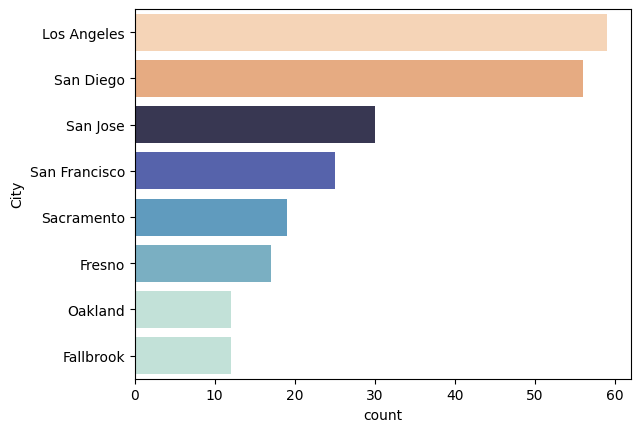

In [ ]:
# Visualize filtered customer per city
plt.figure()
sns.barplot(x = filtered_city_count, y = filtered_city_count.index, hue = filtered_city_count, palette = 'icefire', legend = False)

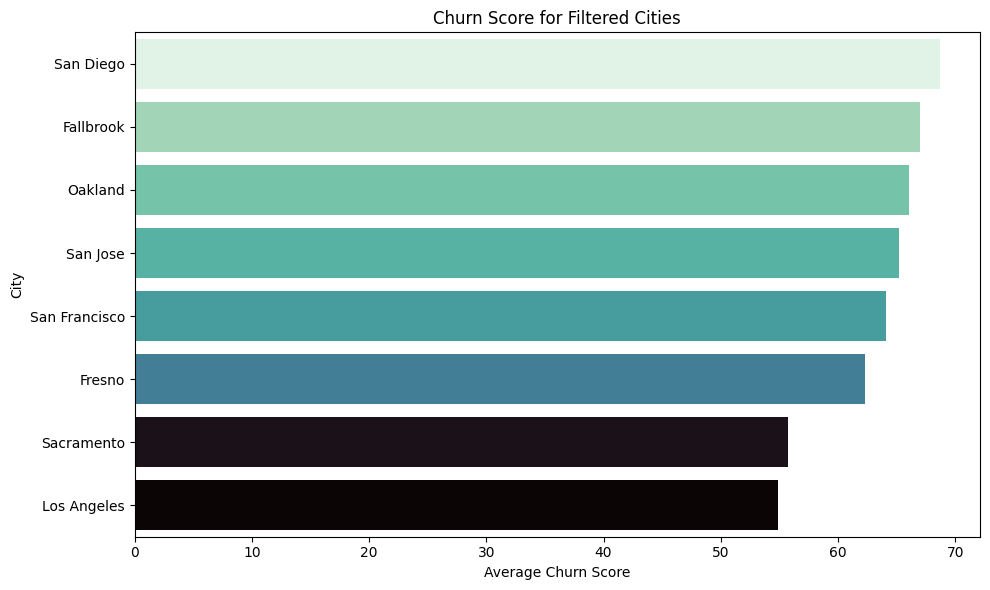

In [ ]:
plt.figure(figsize=(10, 6))
sorted_churn_for_filtered_locations = churn_for_filtered_locations.sort_values(by='Churn Score', ascending=False)
sns.barplot(x = sorted_churn_for_filtered_locations['Churn Score'], y = sorted_churn_for_filtered_locations['City'], hue = sorted_churn_for_filtered_locations['Churn Score'], palette = 'mako', legend = False)
plt.title('Churn Score for Filtered Cities')
plt.xlabel('Average Churn Score')
plt.ylabel('City')
plt.tight_layout()
plt.show()

In [ ]:
# Total Revenue by age range
age_group_revenue = original_df.groupby('Age Group', observed=False)['Total Revenue'].agg(['sum', 'count'])
display(age_group_revenue)

,sum,count
Age Group,,
18-29,843005.25,295
30-39,703484.72,233
40-49,699077.55,253
50-59,748073.07,247
60-69,703865.82,231
70-79,443027.67,136
80+,47693.47,14


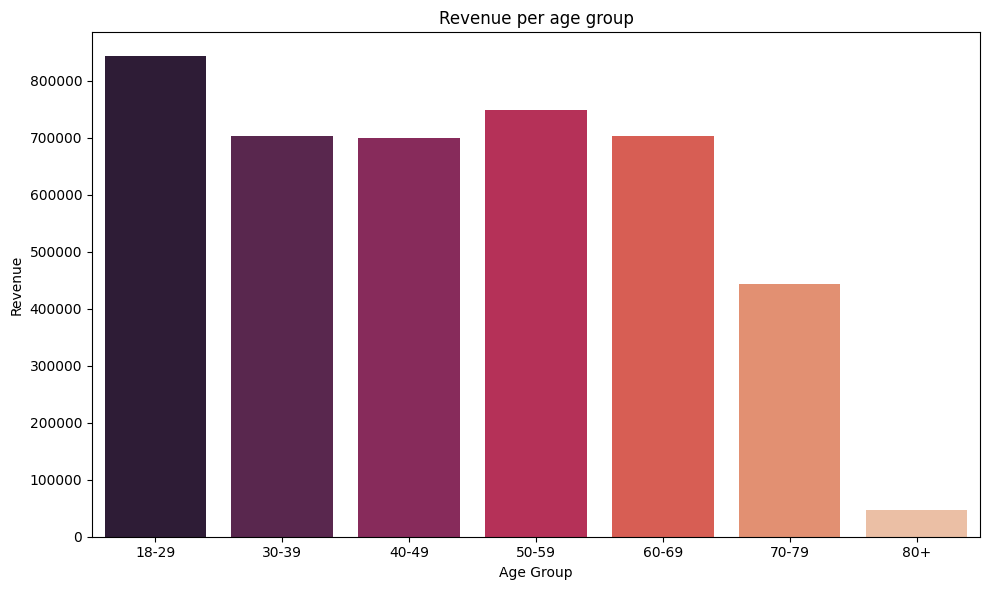

In [ ]:
plt.figure(figsize=(10,6))
sns.barplot(x = age_group_revenue.index, y = age_group_revenue['sum'], hue = age_group_revenue.index, palette = 'rocket', legend = False)
plt.title('Revenue per age group')
plt.xlabel('Age Group')
plt.ylabel('Revenue')
plt.tight_layout()
plt.show()



In [ ]:
city_reveune = original_df.groupby('City')['Total Revenue'].agg(['sum']).sort_values(by='sum', ascending = False)
city_revenue_filtered = city_reveune.head(20)
display(city_revenue_filtered)

,sum
City,
Los Angeles,175944.13
San Diego,151524.96
San Jose,76265.46
Sacramento,69592.27
San Francisco,56981.45
Fresno,44400.54
Oakland,41581.88
Long Beach,32851.21
Riverside,29048.69


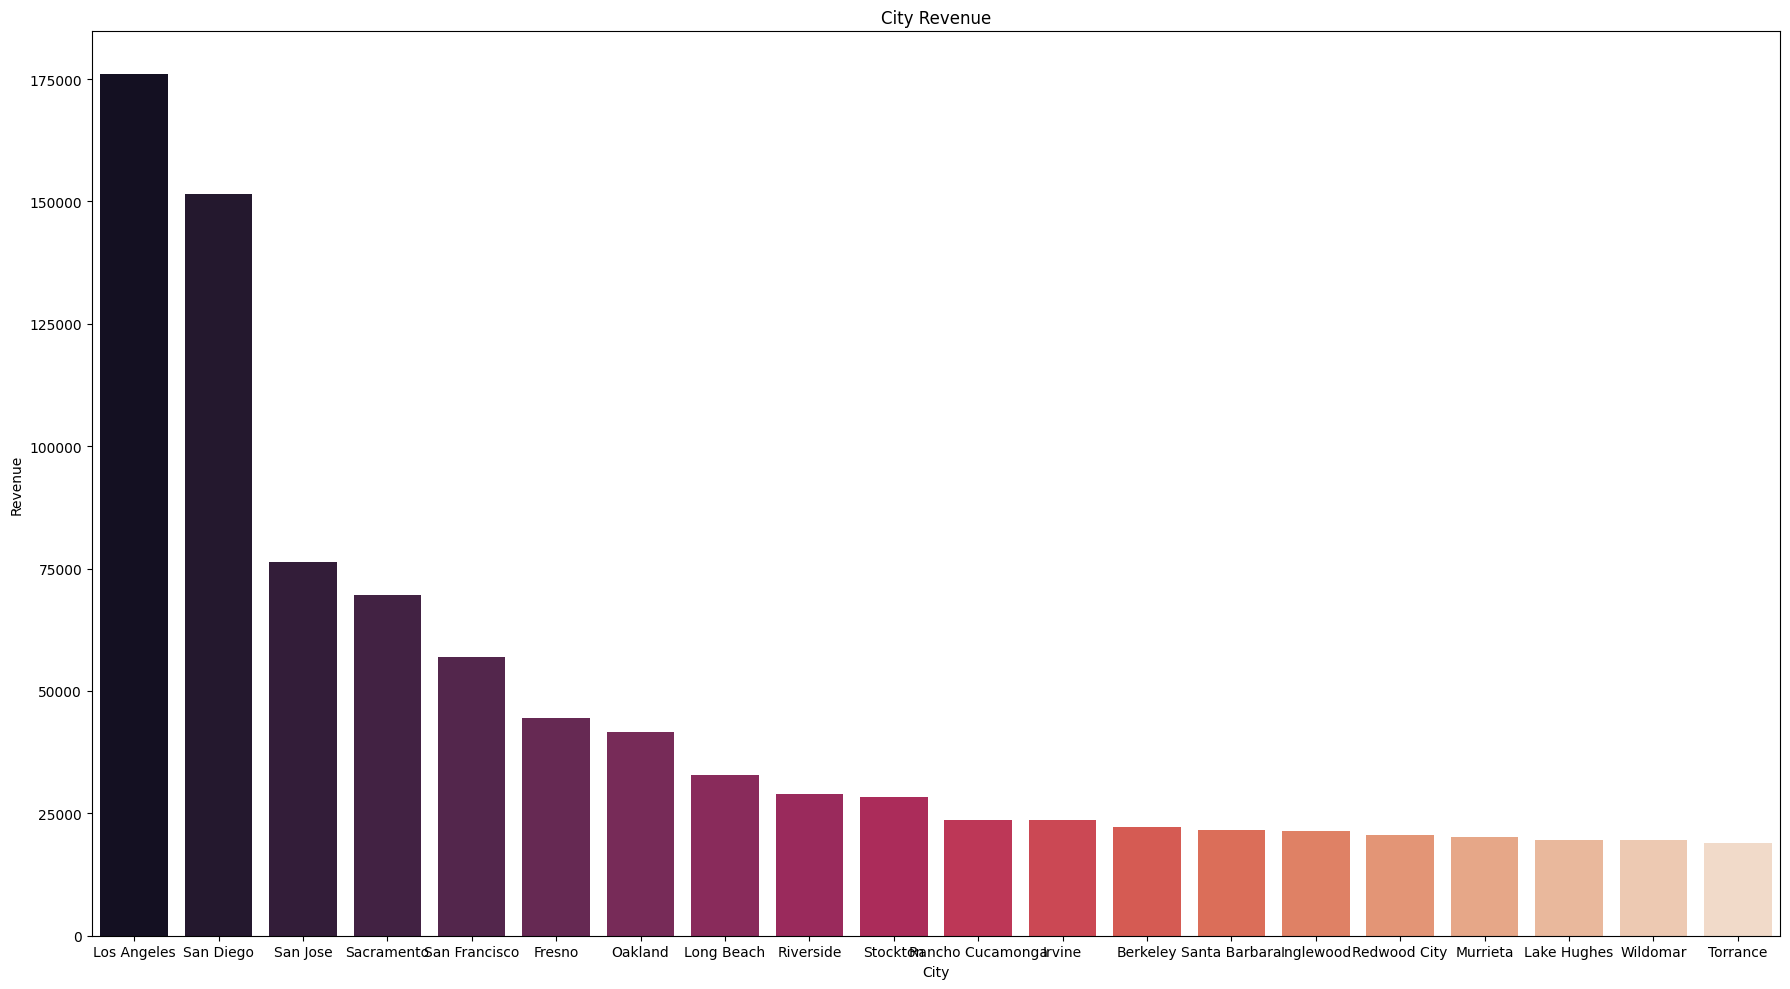

In [ ]:
plt.figure(figsize=(18,10))
sns.barplot(x = city_revenue_filtered.index, y = city_revenue_filtered['sum'], hue = city_revenue_filtered.index, palette = 'rocket')
plt.xlabel('City')
plt.ylabel('Revenue')
plt.title('City Revenue')
plt.tight_layout()
plt.show()